In [1]:
# From ref design
from pynq import Overlay
import xrfclk
from pynq import PL

# ADC
from adc_scope import AdcScope
import matplotlib.pyplot as plt
%matplotlib inline

# DAC
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [2]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals
ol = Overlay("awg_adc_v5.bit")         # after xrfclk.set_ref_clks(...)

In [3]:
awg = AWG(window=1000 * ns, bitfile=ol)

Window = 0.9993 us  (9824 samples, 614 clock cycles)  [requested 1.0000 us]


1e-09 9830400000.0 5.000000000000001e-07 4915 614
Window: 0.9993 us = 9824 samples = 614 clock cycles (MAX_POINTS)
DAC full scale: +-0.250 V peak (CW -2.04 dBm into 50 ohm)
  DAC_B slot z: peak     0.00 mV  (  -inf dBm)
  DAC_B slot x: peak   100.00 mV  (-10.00 dBm)
  DAC_A slot z: peak     0.00 mV  (  -inf dBm)
  DAC_A slot x: peak   100.00 mV  (-10.00 dBm)


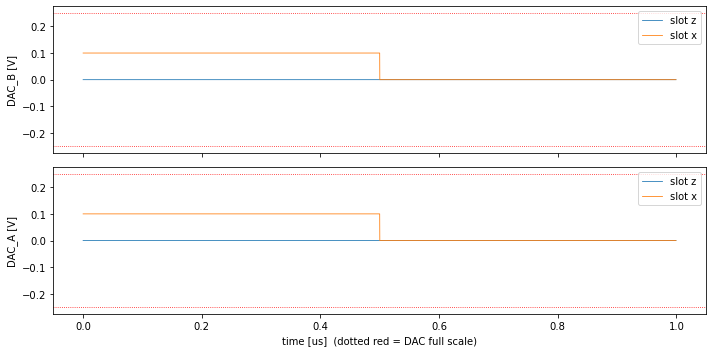

In [16]:
# mysig = 0.2 * np.sin(2*np.pi*100e6*awg.t)  # 164 mV peak

pulse_width = 500 * ns
pulsewidth_insamples = round(pulse_width * DAC_SR)

print(ns, DAC_SR, pulse_width, pulsewidth_insamples, awg.max_points)

mypulse = 0.1 * np.append( np.ones(pulsewidth_insamples), np.zeros(len(awg.t) - pulsewidth_insamples) )

awg.set_waveform("DAC_A", "x", mypulse)
awg.set_waveform("DAC_B", "x", mypulse)
# Not played by default
awg.set_waveform("DAC_A", "z", 0)
awg.set_waveform("DAC_B", "z", 0)
awg.summary()   # peak level of every slot (+ clipping warning)
awg.plot()
plt.show()

In [17]:
# awg.connect()    # load bitstream, program clocks, reset the AWG logic
# awg.upload()     # send waveforms + length to the board RAM
# awg.start()      # enable the outputs

DMA upload took 0.0066 s
Playing slot z on ['DAC_A', 'DAC_B']


In [3]:
sc = AdcScope(ol)                      # starts the ADC clock (MMCM) and checks the ADC streams

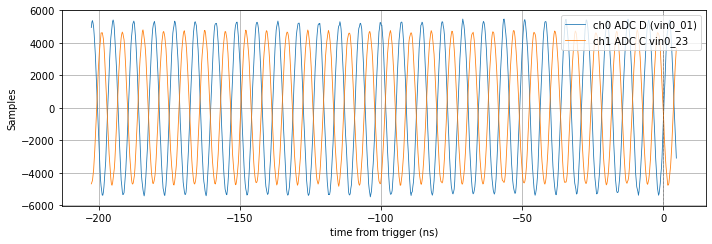

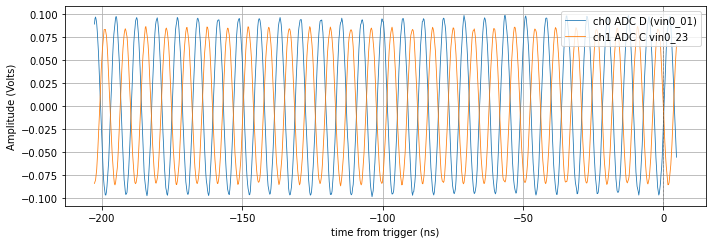

In [4]:
sc.configure(trigger="immediate", level=0.05, pre_ns=200, length_ns=100)
# sc.configure(trigger="awg0", pre_ns=0, length_ns=200)
t, y = sc.acquire() # t in ns, 0 = trigger; y in fraction of full scale

sc.plot(t, y*32768.0, ylabel="Samples")
sc.plot(t, y/1.7, ylabel="Amplitude (Volts)") # Experimentally 0.1V @10MHz gave 0.17FS

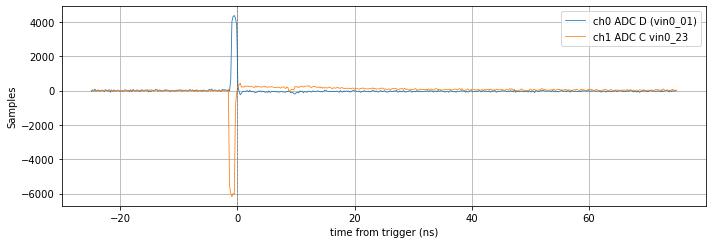

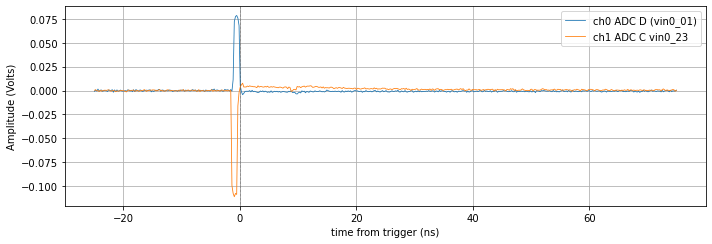

In [12]:
sc.configure(trigger="falling", level=0.05, pre_ns=20, length_ns=100)
# sc.configure(trigger="awg0", pre_ns=0, length_ns=200)
t, y = sc.acquire() # t in ns, 0 = trigger; y in fraction of full scale

sc.plot(t, y*32768.0, ylabel="Samples")
sc.plot(t, y/1.7, ylabel="Amplitude (Volts)") # Experimentally 0.1V @10MHz gave 0.17FS

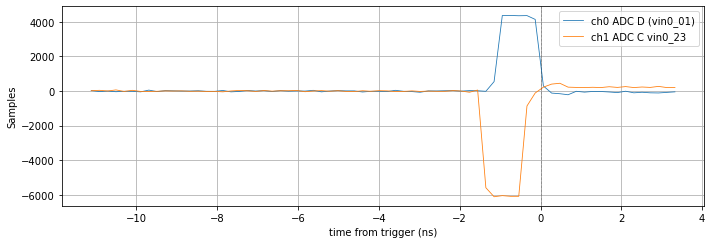

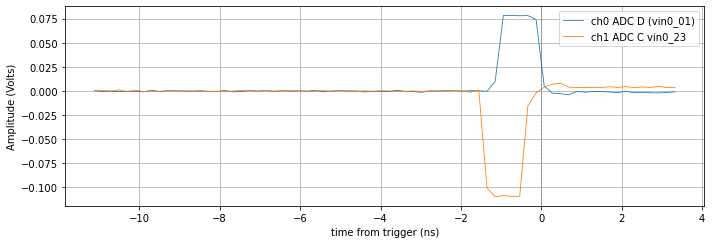

In [14]:
sc.configure(trigger="falling", level=0.05, pre_ns=5, length_ns=10)
# sc.configure(trigger="awg0", pre_ns=0, length_ns=200)
t, y = sc.acquire() # t in ns, 0 = trigger; y in fraction of full scale

sc.plot(t, y*32768.0, ylabel="Samples")
sc.plot(t, y/1.7, ylabel="Amplitude (Volts)") # Experimentally 0.1V @10MHz gave 0.17FS

In [39]:
sc.configure(trigger="awg0", pre_ns=20, length_ns=200)
offset_ns, spread_ns = sc.calibrate_awg0(channel=0)
# print("initial offset DAC->ADC in ns:", offset_ns, "\nspread_ns:", spread_ns)
cpt = 1

while(spread_ns > 0.01): # Means not locked, do again
    offset_ns, spread_ns = sc.calibrate_awg0(channel=0)
    cpt=cpt+1

print("final offset DAC->ADC in ns:", offset_ns, "\nspread_ns:", spread_ns, "\nattempts needed:", cpt)

final offset DAC->ADC in ns: 120.78039657798499 
spread_ns: 0.0008412320475779815 
attempts needed: 1


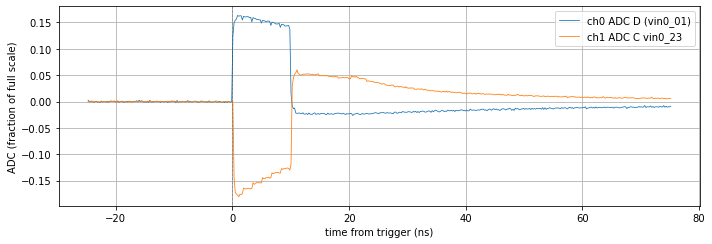

In [40]:
sc.configure(trigger="awg0", pre_ns=-offset_ns+20, length_ns=100)
t, y = sc.acquire()                    # t in ns, 0 = trigger; y in fraction of full scale
sc.plot(t, y)

1e-09 9830400000.0 2.0000000000000002e-07 1966 614
DMA upload took 0.0067 s
Playing slot z on ['DAC_A', 'DAC_B']


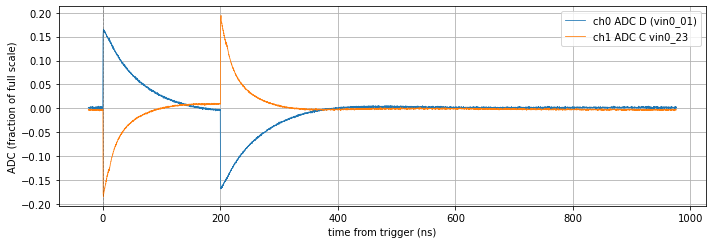

In [45]:
pulse_width = 200 * ns
pulsewidth_insamples = round(pulse_width * DAC_SR)

print(ns, DAC_SR, pulse_width, pulsewidth_insamples, awg.max_points)

mypulse = 0.1 * np.append( np.ones(pulsewidth_insamples), np.zeros(len(awg.t) - pulsewidth_insamples) )

awg.set_waveform("DAC_A", "x", mypulse)
awg.set_waveform("DAC_B", "x", mypulse)
# Not played by default
awg.set_waveform("DAC_A", "z", 0)
awg.set_waveform("DAC_B", "z", 0)

awg.connect()    # load bitstream, program clocks, reset the AWG logic
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs

sc.configure(trigger="awg0", pre_ns=-offset_ns+20, length_ns=1000)
t, y = sc.acquire()                    # t in ns, 0 = trigger; y in fraction of full scale
sc.plot(t, y)